In [1]:
# ── Imports ──
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from scipy.ndimage import zoom

# ── Device ──
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using: {device}")

Using: cuda


In [2]:
import zipfile
import torch
import torchvision.transforms as transforms
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
with zipfile.ZipFile('/kaggle/input/competitions/mdm/mdm_images.zip', 'r') as zip_ref:
    zip_ref.extractall('/kaggle/working/images')

In [3]:
import pandas as pd
labels_df = pd.read_csv('/kaggle/input/competitions/mdm/mdm_training_solution.csv')

In [4]:
print(labels_df.columns)

Index(['GalaxyId', 'e1', 'e2'], dtype='object')


In [5]:


transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])



In [6]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class GalaxyDataset(Dataset):
    def __init__(self, folder, labels_df, transform=None):
        self.folder = folder
        self.transform = transform
        # Read filenames once during initialization
        self.filenames = os.listdir(folder)
        
        # Map GalaxyId to (e1, e2) and store it inside the class
        self.labels_dict = dict(zip(labels_df['GalaxyId'], zip(labels_df['e1'], labels_df['e2'])))

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]
        
        # Extract galaxy_id from filename (e.g., "galaxy_12345.jpg" -> 12345)
        try:
            galaxy_id = int(filename.split(".")[0].split("_")[-1])
            e1, e2 = self.labels_dict[galaxy_id]
        except (KeyError, ValueError) as e:
            raise KeyError(f"Could not find or parse labels for file: {filename}. Error: {e}")
        
        # Load and transform image
        image_path = os.path.join(self.folder, filename)
        img = Image.open(image_path).convert('RGB') # .convert('RGB') ensures 3 channels
        
        if self.transform:
            img_tensor = self.transform(img)
        else:
            img_tensor = img

        # Convert labels to a float tensor for regression tasks
        label_tensor = torch.tensor([e1, e2], dtype=torch.float32)
        
        return img_tensor, label_tensor

# --- Initialization & DataLoader Setup ---

train_dataset = GalaxyDataset(
    folder='/kaggle/working/images/galaxy_postage/training',
    labels_df=labels_df,
    transform=transform
)

from torch.utils.data import random_split 
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_split, val_split = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_split, batch_size=32, shuffle=True)
val_loader = DataLoader(val_split, batch_size=32, shuffle=False)



Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 216MB/s]


Linear(in_features=2048, out_features=2, bias=True)
Epoch 0: train_loss=0.0292  val_loss=0.0252
Epoch 1: train_loss=0.0255  val_loss=0.0253
Epoch 2: train_loss=0.0250  val_loss=0.0244
Epoch 3: train_loss=0.0246  val_loss=0.0242
Epoch 4: train_loss=0.0246  val_loss=0.0254
Epoch 5: train_loss=0.0243  val_loss=0.0242
Epoch 6: train_loss=0.0243  val_loss=0.0242
Epoch 7: train_loss=0.0240  val_loss=0.0257
Epoch 8: train_loss=0.0240  val_loss=0.0237
Epoch 9: train_loss=0.0241  val_loss=0.0241
Epoch 10: train_loss=0.0238  val_loss=0.0237
Epoch 11: train_loss=0.0237  val_loss=0.0239


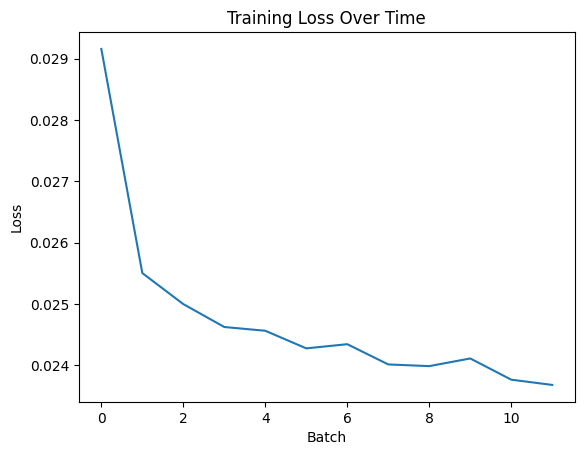

In [7]:
import torch
import torchvision.models as models
import torch.nn as nn

model = models.resnet50(weights='IMAGENET1K_V1')
model.fc = nn.Linear(2048, 2)
print(model.fc)
for param in model.parameters():
    param.requires_grad = False

for params in model.fc.parameters():
    params.requires_grad = True
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.0001)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
train_loss_history = []
val_loss_history = []

for epoch in range(12):
    # Training
    model.train()
    running_train_loss = 0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        predictions = model(x_batch)
        loss = loss_function(predictions, y_batch)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item()
    avg_train_loss = running_train_loss / len(train_loader)
    train_loss_history.append(avg_train_loss)
    
    # Validation (no training, just checking)
    model.eval()
    running_val_loss = 0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            predictions = model(x_batch)
            loss = loss_function(predictions, y_batch)
            running_val_loss += loss.item()
    avg_val_loss = running_val_loss / len(val_loader)
    val_loss_history.append(avg_val_loss)
    
    print(f"Epoch {epoch}: train_loss={avg_train_loss:.4f}  val_loss={avg_val_loss:.4f}")

plt.plot(train_loss_history)
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.title('Training Loss Over Time')
plt.show()
       
        
        



        
        
   

In [8]:
model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(train_loader))
    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)
    predictions = model(x_batch)
    print("Predictions:", predictions[:5])
    print("Actual:", y_batch[:5])
    mae = torch.abs(predictions - y_batch).mean()
    print("MAE:", mae.item())

Predictions: tensor([[-0.0118,  0.0428],
        [ 0.0367,  0.0025],
        [ 0.0083,  0.0170],
        [-0.0273,  0.0179],
        [-0.0066, -0.0395]], device='cuda:0')
Actual: tensor([[ 0.3013,  0.1908],
        [-0.0271, -0.2038],
        [-0.1173, -0.0705],
        [-0.0316,  0.0397],
        [ 0.1782, -0.2110]], device='cuda:0')
MAE: 0.12766847014427185


In [9]:
torch.save(model.state_dict(), '/kaggle/working/resnet50_lensing_model.pt')
print("Model saved!")

Model saved!


In [10]:
def evaluate_with_gaussian_noise(model, data_loader, device, noise_levels=(0.0, 0.05, 0.1, 0.2, 0.3)):
    model.eval()
    results = {}
    
    with torch.no_grad():
        for noise_level in noise_levels:
            total_abs_error = 0
            total_count = 0
            for x_batch, y_batch in data_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                
                if noise_level > 0:
                    noise = torch.randn_like(x_batch) * noise_level
                    x_batch = x_batch + noise
                
                predictions = model(x_batch)
                total_abs_error += torch.abs(predictions - y_batch).sum().item()
                total_count += y_batch.numel()
            
            mae = total_abs_error / total_count
            results[noise_level] = mae
            print(f"Noise level {noise_level}: MAE = {mae:.4f}")
    
    return results

In [11]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)
    
    def _save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate(self, input_tensor, output_index=0):
        self.model.eval()
        input_tensor = input_tensor.unsqueeze(0) if input_tensor.dim() == 3 else input_tensor
        input_tensor.requires_grad_()
        
        output = self.model(input_tensor)
        target = output[0, output_index]
        
        self.model.zero_grad()
        target.backward()
        
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

In [12]:
noise_results = evaluate_with_gaussian_noise(model, val_loader, device)

Noise level 0.0: MAE = 0.1241
Noise level 0.05: MAE = 0.2936
Noise level 0.1: MAE = 0.4501
Noise level 0.2: MAE = 1.3988
Noise level 0.3: MAE = 2.4525


Heatmap shape: (7, 7)


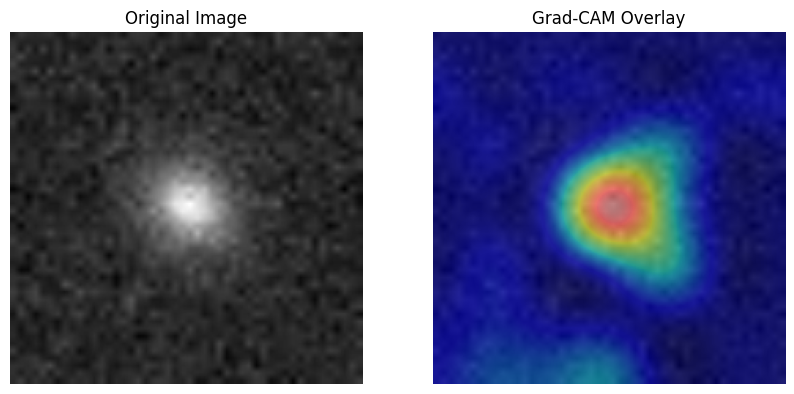

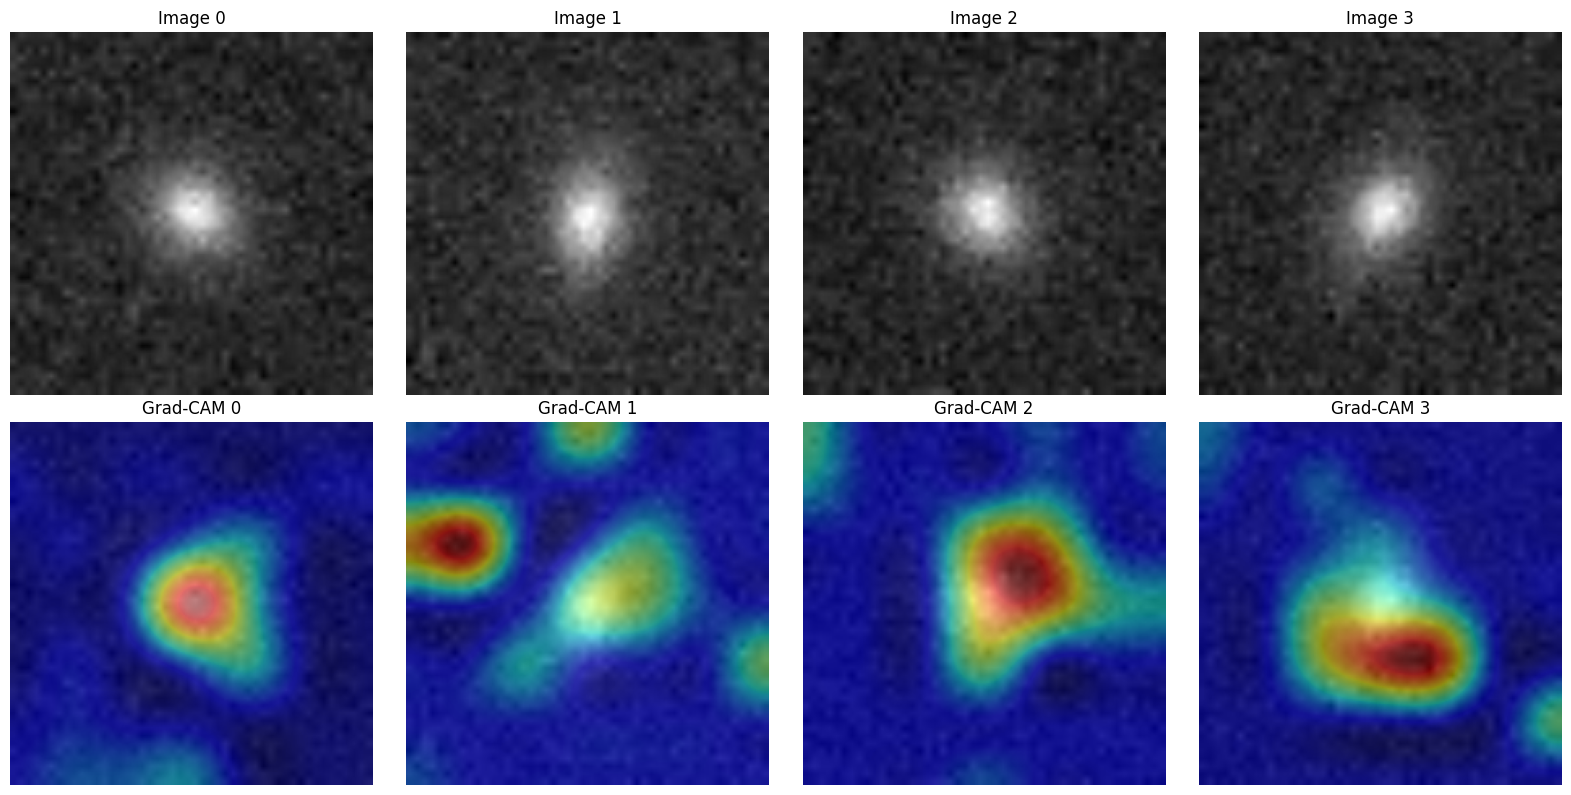

In [13]:
gradcam = GradCAM(model, target_layer=model.layer4[-1])
x_sample, y_sample = next(iter(val_loader))
x_sample, y_sample = x_sample.to(device), y_sample.to(device)
single_image = x_sample[0]
heatmap = gradcam.generate(single_image, output_index=0)
print("Heatmap shape:", heatmap.shape)
import numpy as np
from scipy.ndimage import zoom

# Resize the 7x7 heatmap up to 224x224 using simple interpolation
zoom_factor = 224 / heatmap.shape[0]
heatmap_resized = zoom(heatmap, zoom_factor)

# Get the original image in displayable format (move channels, denormalize if needed)
original_image = single_image.cpu().permute(1, 2, 0).numpy()
original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap='jet', alpha=0.5)
plt.title("Grad-CAM Overlay")
plt.axis('off')

plt.show()
x_batch, y_batch = next(iter(val_loader))
x_batch, y_batch = x_batch.to(device), y_batch.to(device)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    single_image = x_batch[i]
    heatmap = gradcam.generate(single_image, output_index=0)
    
    zoom_factor = 224 / heatmap.shape[0]
    heatmap_resized = zoom(heatmap, zoom_factor)
    
    original_image = single_image.cpu().permute(1, 2, 0).numpy()
    original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())
    
    axes[0, i].imshow(original_image)
    axes[0, i].set_title(f"Image {i}")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(original_image)
    axes[1, i].imshow(heatmap_resized, cmap='jet', alpha=0.5)
    axes[1, i].set_title(f"Grad-CAM {i}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [14]:
!pip install gdown

!gdown 1doUhVoq1-c9pamZVLpvjW1YRDMkKO1Q5
!ls /kaggle/working/


Downloading...
From (original): https://drive.google.com/uc?id=1doUhVoq1-c9pamZVLpvjW1YRDMkKO1Q5
From (redirected): https://drive.google.com/uc?id=1doUhVoq1-c9pamZVLpvjW1YRDMkKO1Q5&confirm=t&uuid=b7d6baee-3d3c-4e72-8253-25268e3e5a6d
To: /kaggle/working/lens-finding-test.zip
100%|██████████████████████████████████████| 2.11G/2.11G [00:25<00:00, 82.4MB/s]
images	lens-finding-test.zip  __notebook__.ipynb  resnet50_lensing_model.pt


In [15]:
import zipfile

with zipfile.ZipFile('/kaggle/working/lens-finding-test.zip', 'r') as zip_ref:
    zip_ref.extractall('/kaggle/working/deeplense/')

In [16]:
import os
print(os.listdir('/kaggle/working/deeplense/'))

['__MACOSX', 'train_nonlenses', 'train_lenses', 'test_nonlenses', 'test_lenses']


In [17]:
import os
sample_files = os.listdir('/kaggle/working/deeplense/train_lenses')[:5]
print(sample_files)
print(f"Total train lenses: {len(os.listdir('/kaggle/working/deeplense/train_lenses'))}")
print(f"Total train non-lenses: {len(os.listdir('/kaggle/working/deeplense/train_nonlenses'))}")
for root, dirs, files in os.walk('/kaggle/working/deeplense/train_lenses'):
    print(root)
    print(files[:3])
    break

['1198.npy', '257.npy', '422.npy', '1570.npy', '1199.npy']
Total train lenses: 1730
Total train non-lenses: 28675
/kaggle/working/deeplense/train_lenses
['1198.npy', '257.npy', '422.npy']


In [18]:
import numpy as np 
sample = np.load('/kaggle/working/deeplense/train_lenses/106.npy')
print(sample.shape)
print(sample.dtype)

(3, 64, 64)
float32


In [19]:
from torch.utils.data import Dataset, DataLoader

In [20]:
class DeepLenseDataset(Dataset):
    def __init__(self, transform=None):
        self.transform = transform
        self.samples = []
        
        for filename in os.listdir('/kaggle/working/deeplense/train_lenses'):
            filepath = os.path.join('/kaggle/working/deeplense/train_lenses', filename)
            self.samples.append((filepath, 1))
            
        for filename in os.listdir('/kaggle/working/deeplense/train_nonlenses'):
            filepath = os.path.join('/kaggle/working/deeplense/train_nonlenses', filename)
            self.samples.append((filepath, 0))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        filepath, label = self.samples[idx]
        image = np.load(filepath)
        img_tensor = torch.tensor(image, dtype=torch.float32)
        
        if self.transform:
            img_tensor = self.transform(img_tensor)
        
        return img_tensor, label

In [21]:
import torchvision.transforms as transforms

In [22]:
deeplense_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

deeplense_dataset = DeepLenseDataset(transform=deeplense_transform)
print(len(deeplense_dataset))

deeplense_loader = DataLoader(deeplense_dataset, batch_size=32, shuffle=True)

30405


In [23]:
import torch.autograd as autograd

class GradientReversalFunction(autograd.Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.view_as(x)
    
    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.lambda_, None

class GradientReversalLayer(nn.Module):
    def __init__(self, lambda_=1.0):
        super().__init__()
        self.lambda_ = lambda_
    
    def forward(self, x):
        return GradientReversalFunction.apply(x, self.lambda_)

In [24]:
class DANNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = models.resnet50(weights='IMAGENET1K_V1')
        self.backbone.fc = nn.Identity()
        self.regression_head = nn.Linear(2048, 2)
        self.grl = GradientReversalLayer()
        self.domain_classifier = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Linear(256, 2)
        )
    def forward(self, x):
        features = self.backbone(x)
    
        reg_output = self.regression_head(features)
    
        reversed_features = self.grl(features)
        domain_output = self.domain_classifier(reversed_features)
        # also missing self!
    
    
        return reg_output, domain_output

In [25]:
# DANN Training Loop (fixed - iterator outside batch loop)
dann_model = DANNModel().to(device)
dann_optimizer = torch.optim.Adam(dann_model.parameters(), lr=0.0001, weight_decay=1e-4)
regression_loss_fn = nn.MSELoss()
domain_loss_fn = nn.CrossEntropyLoss()

for epoch in range(11):
    dann_model.train()
    target_iter = iter(deeplense_loader)  # created ONCE per epoch, not per batch
    
    running_reg_loss = 0
    running_domain_loss = 0
    
    for x_source, y_source in train_loader:
        # Get target batch, reset iterator if exhausted
        try:
            x_target, _ = next(target_iter)
        except StopIteration:
            target_iter = iter(deeplense_loader)
            x_target, _ = next(target_iter)
        
        # Move to device
        x_source = x_source.to(device)
        y_source = y_source.to(device)
        x_target = x_target.to(device)
        
        # Synthetic domain labels
        domain_labels_source = torch.zeros(x_source.size(0), dtype=torch.long).to(device)
        domain_labels_target = torch.ones(x_target.size(0), dtype=torch.long).to(device)
        
        # Forward passes
        reg_pred, domain_pred_source = dann_model(x_source)
        _, domain_pred_target = dann_model(x_target)
        
        # Losses
        reg_loss = regression_loss_fn(reg_pred, y_source)
        domain_loss = domain_loss_fn(domain_pred_source, domain_labels_source) + \
                      domain_loss_fn(domain_pred_target, domain_labels_target)
        total_loss = reg_loss + domain_loss
        
        # Backprop
        dann_optimizer.zero_grad()
        total_loss.backward()
        dann_optimizer.step()
        
        running_reg_loss += reg_loss.item()
        running_domain_loss += domain_loss.item()
    
    avg_reg = running_reg_loss / len(train_loader)
    avg_domain = running_domain_loss / len(train_loader)
    print(f"Epoch {epoch}: reg_loss={avg_reg:.4f}  domain_loss={avg_domain:.4f}")

Epoch 0: reg_loss=0.0247  domain_loss=1.4486
Epoch 1: reg_loss=0.0246  domain_loss=1.3947
Epoch 2: reg_loss=0.0239  domain_loss=1.3893
Epoch 3: reg_loss=0.0237  domain_loss=1.3887
Epoch 4: reg_loss=0.0230  domain_loss=1.3864
Epoch 5: reg_loss=0.0234  domain_loss=1.3870
Epoch 6: reg_loss=0.0231  domain_loss=1.3865
Epoch 7: reg_loss=0.0229  domain_loss=1.3863
Epoch 8: reg_loss=0.0240  domain_loss=1.3942
Epoch 9: reg_loss=0.0236  domain_loss=1.3884
Epoch 10: reg_loss=0.0233  domain_loss=1.3882


In [26]:
def evaluate_with_gaussian_noise(dann_model, data_loader, device, noise_levels=(0.0, 0.05, 0.1, 0.2, 0.3)):
    dann_model.eval()
    results = {}
    
    with torch.no_grad():
        for noise_level in noise_levels:
            total_abs_error = 0
            total_count = 0
            for x_batch, y_batch in data_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                
                if noise_level > 0:
                    noise = torch.randn_like(x_batch) * noise_level
                    x_batch = x_batch + noise
                
                predictions, _ = dann_model(x_batch)
                total_abs_error += torch.abs(predictions - y_batch).sum().item()
                total_count += y_batch.numel()
            
            mae = total_abs_error / total_count
            results[noise_level] = mae
            print(f"Noise level {noise_level}: MAE = {mae:.4f}")
    
    return results

In [27]:
noise_results = evaluate_with_gaussian_noise(dann_model, val_loader, device)

Noise level 0.0: MAE = 0.1217
Noise level 0.05: MAE = 0.1232
Noise level 0.1: MAE = 0.1304
Noise level 0.2: MAE = 0.3091
Noise level 0.3: MAE = 0.5675
